## Overfit & Underfit

* Underfitting: the model is too simple to capture the real pattern.

* Overfitting: the model memorises the training rows, including their noise (random accidents that won’t repeat).

* Good fit: Understood the pattern, does well on both.

* Underfit leads to high bias while overfit leads to high variance

* Underfit more complex: deeper tree and more features
* Overfit less complex: limit tree, reguralise and more data
* Good fit: it stops and don't tune forever

## Bias and variance (the two words behind the table)

* High Bias: Every dart lands in a tight group, but off-centre. The player’s assumptions are wrong in a consistent way. A tree with only one question is like this: it can’t express the real pattern, however much data you give it.

* High Variance: The darts scatter widely and the average is near the target. The model reacts to every accident in the particular sample it saw. Give it different training rows and you get a very different model. An unlimited tree is like this.

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score)


In [3]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

In [4]:
print(df.shape)

(7043, 21)


In [5]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["churn"] = (df["Churn"] == "Yes").astype(int)

num = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
cat = ["Contract", "InternetService", "PaymentMethod",
           "PaperlessBilling", "Partner", "Dependents", "TechSupport"]
X = pd.get_dummies(df[num + cat], columns=cat, dtype=int)
y = df["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42, stratify=y_train
)

print(X.shape, X.isna().sum().sum(), round(y.mean(), 4))
print(X_train.shape, X_test.shape, X_tr.shape, X_val.shape)
print(y_val.sum(), y_test.sum())

(7043, 23) 11 0.2654
(5634, 23) (1409, 23) (4225, 23) (1409, 23)
374 374


In [6]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score

In [10]:
def make_tree(**kw):
    return Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(random_state=42, **kw))
    ])

def score(model):
    model.fit(X_tr, y_tr)
    p_tr = model.predict_proba(X_tr)[:, 1]
    p_val = model.predict_proba(X_val)[:, 1]
    return dict(train_acc=model.score(X_tr, y_tr), val_acc=model.score(X_val, y_val),
                train_auc=roc_auc_score(y_tr, p_tr), val_auc=roc_auc_score(y_val, p_val))

In [11]:
models = {
    "simple (depth 1)": make_tree(max_depth=1),
    "medium (depth 5)": make_tree(max_depth=5),
    "complex (no limit)": make_tree()
}

rows = []
for name, m in models.items():
    r = score(m)
    r["leaves"] = m.named_steps["model"].get_n_leaves()
    r["model"] = name
    rows.append(r)
res = pd.DataFrame(rows).set_index("model")
res["acc_gap"] = res["train_acc"] - res["val_acc"]
res["auc_gap"] = res["train_auc"] - res["val_auc"]
print(res[["leaves", "train_acc", "val_acc", "acc_gap", "train_auc", "val_auc", "auc_gap"]].round(4))

                    leaves  train_acc  val_acc  acc_gap  train_auc  val_auc  \
model                                                                         
simple (depth 1)         2     0.7347   0.7346   0.0001     0.7336   0.7148   
medium (depth 5)        30     0.8088   0.7885   0.0203     0.8549   0.8137   
complex (no limit)     848     0.9979   0.7353   0.2626     1.0000   0.6657   

                    auc_gap  
model                        
simple (depth 1)     0.0189  
medium (depth 5)     0.0412  
complex (no limit)   0.3343  


In [14]:
from sklearn.tree import export_text
m1 =  make_tree(max_depth=1).fit(X_tr, y_tr)
print("predicts churn for", int(m1.predict(X_val).sum()), "of", len(X_val))
print(export_text(m1.named_steps["model"], feature_names=list(X.columns)))

predicts churn for 0 of 1409
|--- Contract_Month-to-month <= 0.50
|   |--- class: 0
|--- Contract_Month-to-month >  0.50
|   |--- class: 0



best depth 4 0.8201


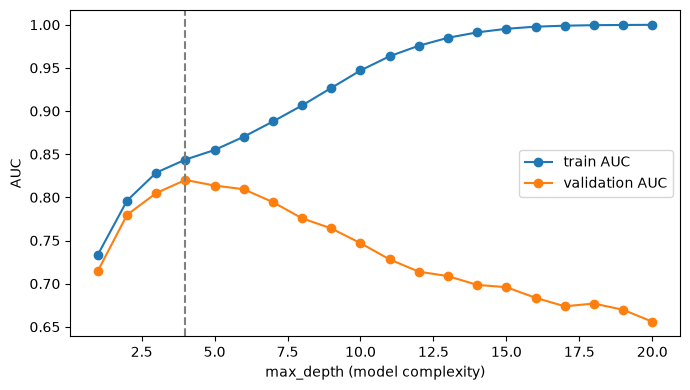

In [16]:
depths = list(range(1,21))
tr_auc, va_auc = [], []
for d in depths:
    r = score(make_tree(max_depth=d))
    tr_auc.append(r["train_auc"]); va_auc.append(r["val_auc"])
best = depths[int(np.argmax(va_auc))]
print("best depth", best, round(max(va_auc), 4))

plt.figure(figsize=(7, 4))
plt.plot(depths, tr_auc, marker="o", label="train AUC")
plt.plot(depths, va_auc, marker="o", label="validation AUC")
plt.axvline(best, linestyle="--", color="grey")
plt.xlabel("max_depth (model complexity)"); plt.ylabel("AUC")
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
rng = np.random.default_rng(0)
res = {"depth 4": [], "no limit": []}
preds = {"depth 4": [], "no limit": []}
for seed in range(8):
    idx = rng.choice(len(X_tr), size=int(0.8*len(X_tr)), replace=False)
    Xs, ys = X_tr.iloc[idx], y_tr.iloc[idx]
    for name, kw in [("depth 4", dict(max_depth=4)), ("no limit", {})]:
        m = make_tree(**kw).fit(Xs, ys)
        p = m.predict_proba(X_val)[:, 1]
        res[name].append(roc_auc_score(y_val, p))
        preds[name].append(p)

for name in res:
    a = np.array(res[name])
    P = np.array(preds[name])
    print(name, "val AUC min/max", a.min().round(4), a.max().round(4), "std", a.std().round(4),
            "| avg per-customer prob std", P.std(axis=0).mean().round(4))

depth 4 val AUC min/max 0.8133 0.825 std 0.0034 | avg per-customer prob std 0.0477
no limit val AUC min/max 0.6367 0.6625 std 0.007 | avg per-customer prob std 0.2273


## Regularization, explained simply
* Regularization means adding a penalty for complexity, so the model has to justify every extra twist.
    - new loss = original loss + penalty × (sum of squared weights)

* Big weights mean the model is bending hard to fit every wiggle, which is memorising.

* The penalty makes big weights expensive, so the weights shrink and the curve gets smoother.

* In scikit-learn the strength is set by C, which works backwards. Small C = strong penalty (simpler model). Large C = weak penalty (free to memorise).

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

def make_lr(C, degree):
    steps = [("imp", SimpleImputer(strategy="median"))]
    if degree > 1:
        steps.append(("poly", PolynomialFeatures(degree=degree, include_bias=False)))
    steps += [("sc", StandardScaler()), ("model", LogisticRegression(C=C, max_iter=5000))]
    return Pipeline(steps)

rows = []
for C in [0.0001, 0.001, 0.01, 0.1, 1, 1000]:
    m = make_lr(C, 3)
    r = score(m)
    w = m.named_steps["model"].coef_[0]
    rows.append(dict(C=C, n_features=len(w), weight_size=np.abs(w).mean(),
                     train_auc=r["train_auc"], val_auc=r["val_auc"],
                     gap=r["train_auc"] - r["val_auc"]))
out = pd.DataFrame(rows).set_index("C")
print(out.round(4).to_string())

           n_features  weight_size  train_auc  val_auc     gap
C                                                             
0.0001           2599       0.0019     0.8493   0.8289  0.0204
0.0010           2599       0.0041     0.8636   0.8285  0.0350
0.0100           2599       0.0109     0.8776   0.8153  0.0623
0.1000           2599       0.0304     0.8893   0.8006  0.0887
1.0000           2599       0.0790     0.8982   0.7892  0.1090
1000.0000        2599       0.6593     0.9079   0.7745  0.1334


##  Your toolbox (the two problems, side by side)
## Problem	              Symptom	                        Fixes 
  Underfit 	             Train low, 	              More complex model, 
(high bias)             validation low                better features, 
                                                      weaker regularization
              

  Overfit 	             Train high, 	              More data, simpler model, 
(high variance)          validation                   stronger regularization, average many models
                         much lower
                         